In [ ]:
from helpers.read_ldf import readLDFdata
from helpers.read_ami import readAMIdata
ami = readAMIdata("./data/angela")
ldf = readLDFdata("./data/angela")


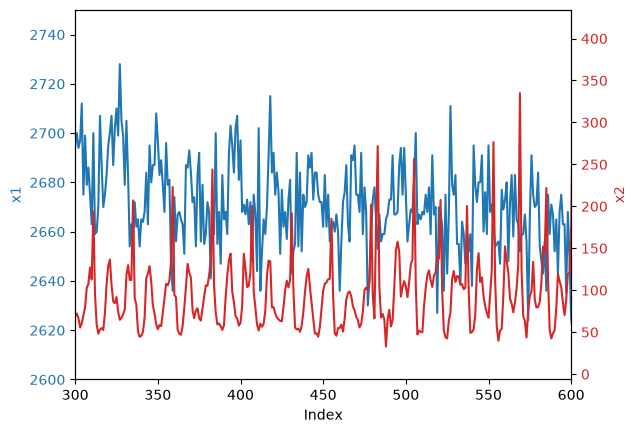

In [74]:
import matplotlib.pyplot as plt
fig, ax1 = plt.subplots()

ax1.plot(range(1, 632), ami, color='tab:blue')
ax1.set_ylabel('x1', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_ylim(2600, 2750)

ax2 = ax1.twinx()  # second axes sharing the same x
ax2.plot(range(1, 632), ldf, color='tab:red')
ax2.set_ylabel('x2', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')


ax1.set_xlim(300,600)
ax1.set_xlabel('Index')
plt.show()

In [58]:
import numpy as np


# Compute cross-correlation
correlation = np.correlate(ldf, ami, mode='full')

# Calculate lags
lags = np.arange(-len(ami) + 1, len(ldf))

# Find the lag with maximum correlation
max_corr_lag = lags[np.argmax(correlation)]
print(f"Maximum correlation at lag: {max_corr_lag}")

Maximum correlation at lag: 3


In [73]:
from scipy.ndimage import gaussian_filter1d
from scipy.stats import pearsonr
import numpy as np

def smooth_cross_correlation(x, y, sigma=5, max_lag=30):
    x = gaussian_filter1d(np.asarray(x, dtype=float), sigma)
    y = gaussian_filter1d(np.asarray(y, dtype=float), sigma)

    results = []

    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            a, b = x[:lag], y[-lag:]
        elif lag > 0:
            a, b = x[lag:], y[:-lag]
        else:
            a, b = x, y

        if len(a) < 3 or np.std(a) == 0 or np.std(b) == 0:
            results.append(np.nan)
        else:
            results.append(pearsonr(a, b).statistic)

    results = np.array(results)
    best_index = np.nanargmax(results)

    return {
        "correlation": results[best_index],
        "lag": best_index - max_lag
    }

result = smooth_cross_correlation(
    ldf[300:600],
    ami[300:600],
    sigma=5,
    max_lag=3
)

print(result)

{'correlation': np.float64(-0.33603447494742894), 'lag': np.int64(3)}
